### Auto-Generated Code Cells

The following code cells contain code from external .py files that has been automatically added to remove these dependencies. This allows you to run this version of the SELENE notebook on Cloud platforms such as Google Colab. Run all following code cells before starting with the actual notebook content. 

Most Cloud platforms such as Google Colab have a wide range of Python packages preinstalled. However, if any import statements in the following code cells throws an error because of a missing package, you can create and run a new code cell to install the missing package using the `pip` command as shown here:
```
!pip install <package-name>
```

You can use the code cell below for convenience.

In [ ]:
#!pip install <package-name>

In [ ]:
# === Inline content for module src.utils.compute.gpu  ==

# === Inlined imports ===
import torch
import random

# === Embedded configs ===


# === Inlined definitions ===
def select_device(force_cpu=False, required_memory_gb=None):
    if force_cpu == True:
        return torch.device('cpu')
    candidate_gpus = []
    for i in range(torch.cuda.device_count()):
        free, total = torch.cuda.mem_get_info(device=i)
        if required_memory_gb is None or free / (1024 * 1024 * 1024) > required_memory_gb:
            candidate_gpus.append((i, free))
    if len(candidate_gpus) == 0:
        return torch.device('cpu')
    else:
        device = torch.cuda.device(random.choice(candidate_gpus)[0])
        return torch.device(f'cuda:{device.idx}')

In [ ]:
# === Inline content for module src.utils.data.files  ==

# === Inlined imports ===
from tqdm import tqdm
import requests
import bz2
import zipfile, tarfile
import os, re, yaml

# === Embedded configs ===
CONFIG = yaml.safe_load("""urls:
  downloads:
    notebooks: "https://github.com/chrisvdweth/selene/tree/master/notebooks"
    datasets: "https://chrisvdw.net/projects/selene/downloads/datasets/"
    models: "https://chrisvdw.net/projects/selene/downloads/models/"
    """)

# === Inlined definitions ===
def create_folder(folder_name, exist_ok=True):
    try:
        os.makedirs(folder_name, exist_ok=exist_ok)
        return folder_name
    except:
        return None

# Fine-Tuning BERT for Classification

Large pretrained language models like BERT have become the standard starting point for modern NLP. Trained on huge amounts of unlabeled text, they learn general-purpose representations of language that capture syntax, semantics, and context. Rather than training a model from scratch, which would require enormous data and compute, we can fine-tune such a model on a comparatively small labeled dataset and adapt it to a specific task. This notebook demonstrates that process for sentiment analysis: given a piece of text, decide whether its sentiment is positive or negative.

The goal here is not to reach state-of-the-art results or to squeeze out the last fraction of a percent through extensive hyperparameter tuning. Instead, we want to walk carefully through every step required for fine-tuning, so that nothing feels like a black box. We load and tokenize the data, set up the pretrained model with a classification head, establish a baseline by evaluating before training, implement a basic training loop and compare it with the Hugging Face `Trainer`, monitor progress, and finally use the model to make predictions on new inputs. Along the way, we look at why each component is needed and how the pieces fit together.

Although the example is sentiment analysis, these steps generalize directly to almost any text classification task, such as topic labeling, spam detection, intent recognition, or toxicity detection. Classification is one of the most common problems in applied NLP, and the workflow stays largely the same: only the dataset, the label set, and the number of output classes change. Understanding this recipe once therefore pays off many times over, making it a worthwhile foundation for anyone who wants to work with pretrained language models.

### Setting up the Notebook

#### Make Required Imports

This notebook requires the import of different Python packages but also additional Python modules that are part of the repository. If a package is missing, use your preferred package manager (e.g., [conda](https://anaconda.org/anaconda/conda) or [pip](https://pypi.org/project/pip/)) to install it. If the code cell below runs with any errors, all required packages and modules have successfully been imported.

In [1]:
import gc
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset

import torch
from torch.utils.data import DataLoader

from transformers import (
    Trainer, 
    TrainingArguments,
    AutoTokenizer,
    BertForSequenceClassification,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
    pipeline,
)

from sklearn.metrics import accuracy_score, f1_score


#### Create Output Folder

When fine-tuning a BERT model, we periodically save the current state of the model to disk. Although the dataset and model used in this notebook is relatively small, we still adopt this best practice of saving the model to avoid losing the training progress in case of any errors or crashes. You can change the output folder by editing the code cell below.

In [2]:
output_folder = create_folder("data/generated/models/bert/")

print(f"Output folder: {output_folder}")

Output folder: data/generated/models/bert/


#### Checking & Setting Computing Device

PyTorch allows to train neural networks on supported GPU to significantly speed up the training process. If you have a support GPU, feel free to utilize it. However, for this notebook it's certainly not needed as our dataset is small and our network model is very simple. We provide an auxiliary method to automatically select the best device. It checks if a supported GPU is available and if so, uses it as the preferred device.

In [3]:
# Select preferred device (GPU, if available; CPU otherwise); you can enfore the use of the CPU
DEVICE = select_device(force_cpu=False)

print("Available device: {}".format(DEVICE))

Available device: cuda:0


#### Preliminaries

This notebook assume a basic understanding of the BERT model and its pretraining.

---

## Introduction

### Text Classification

**Text classification** is the task of assigning one or more predefined labels (classes) to a piece of text, such as a sentence, document, or message. A model learns a mapping from raw text to a category, typically by converting the text into numerical features (e.g., word or sentence embeddings) and then applying a classifier, from logistic regression to fine-tuned transformers or prompted LLMs. Text classification is one of the most frequent tasks in machine learning for a few reasons:

- **Text is everywhere.** Emails, reviews, tickets, chats, contracts, and social posts make up a huge share of the data organizations produce, and most of it is unstructured and needs sorting or routing.
- **Many problems can be reframed as classification.** Anything that reduces to "which bucket does this belong to?" becomes a classification task: sentiment, intent, topic, urgency, toxicity, language, and so on.
- **It is a building block for larger systems.** Chatbots classify intents, search engines classify queries, and LLM pipelines use classifiers for routing, guardrails, and filtering.
- **It is the template for classification in general.** The core ideas (labeled data, feature representation, train/validation/test splits, precision/recall/F1, class imbalance, thresholds) apply identically to images, audio, tabular data, and sensor signals. Text classification is often where practitioners first learn and benchmark these concepts, and modern techniques like transfer learning and pretrained embeddings were popularized in this setting before spreading to other modalities.
- **Labels are often cheap to obtain.** Compared to many other tasks, it is relatively easy to get or approximate labels (user feedback, tags, folders, ratings), which makes supervised learning practical.

The table below shows some where common applications that heavily rely on text classification. From those example, one can make the argument that you "use" text classifiers more or less on a daily basis, even if it is just to keep your email inbox clean.

| Application | How text classification is used |
|---|---|
| **Spam and phishing detection** | Emails and messages are classified as spam/ham or malicious/benign based on content, wording, and links. |
| **Sentiment analysis** | Reviews, tweets, and survey responses are labeled positive, negative, or neutral to track brand perception and product feedback. |
| **Customer support ticket routing** | Incoming tickets are classified by topic, urgency, or department so they reach the right team quickly. |
| **Intent detection in chatbots and assistants** | User utterances are mapped to intents (e.g., "cancel order", "check balance") that trigger the right action or response. |
| **Content moderation** | Posts and comments are flagged for hate speech, harassment, violence, or other policy violations. |
| **Document and news categorization** | Articles, legal documents, and papers are assigned to topics or categories for organization, search, and recommendations. |
| **Language identification** | Text is classified by language to select the right translation, tokenizer, or downstream model. |
| **Medical and clinical text coding** | Clinical notes are classified into diagnosis or billing codes (e.g., ICD codes) to support documentation and analytics. |
| **Fraud and compliance monitoring** | Transaction descriptions, communications, and contracts are screened for suspicious or non-compliant content. |
| **Search query classification** | Queries are categorized by intent (navigational, informational, transactional) to improve ranking and ad targeting. |

In this notebook, we fine-tune a pretrained BERT model for sentiment analysis (e.g., classifying movie reviews as positive or negative). It's a good learning example because the task is intuitive, labeled datasets like IMDb and SST-2 are readily available, it's widely used in practice, and BERT's pretrained language understanding means fine-tuning needs relatively little data and compute.

Despite the focus on sentiment analysis here, the same workflow applies to any classification task: prepare and split the data, tokenize, add a classification head, fine-tune, and evaluate with metrics like accuracy and F1. For tasks like spam detection or intent classification, you mainly swap the dataset and label set, and the principles even carry over to images or audio with a different pretrained backbone.

### BERT in a Nutshell

To understand how fine-tuning a pretrained BERT model works and what it requires from our data, it helps to first recap BERT's basic idea and architecture. Fine-tuning reuses the pretrained encoder and only adds a small task-specific head, so knowing what the encoder expects as input (tokenized, single or paired segments with special tokens) and what it produces (a contextual embedding for every token) explains why the dataset must be prepared in a particular way and why a token classification head can sit directly on top of its outputs.

#### Goal: Contextual Word Embeddings

BERT's goal is to learn **contextual word embeddings**: instead of assigning each word one fixed vector, it computes a representation for every token that depends on the entire sentence. The word *"bank"* therefore gets different vectors in *"river bank"* and *"bank account"*, which lets the model handle ambiguity, syntax, and long-range dependencies far better than static embeddings such as Word2Vec. These embeddings are so useful because they are learned from huge amounts of unlabeled text through the proxy tasks MLM and NSP &mdash; see below &mdash; and can then be reused for many tasks, either as features for other models or by fine-tuning the pretrained encoder with a small task-specific head on limited labeled data.

Architecturally, BERT is based on an **encoder-only Transformer**, whose self-attention lets every token attend directly to every other token in the sequence, in both directions. This typically outperforms earlier contextual models such as ELMo, which relies on recurrent networks (LSTMs). Those process text sequentially, are harder to parallelize, and struggle more with long-range dependencies. Moreover, ELMo only concatenates separately trained left-to-right and right-to-left representations, whereas BERT's encoder conditions on both sides jointly in every layer. The result is richer contextual embeddings and, in practice, stronger performance across a wide range of NLP tasks.

#### Learning Objectives

##### Masked Language Model (MLM)

The MLM learning objective directly implements the **Distributional Hypothesis** which says that a word's meaning is determined by the contexts in which it appears. MLM implements this almost literally: a word is hidden, and the model must predict it using only the surrounding words, left and right. To do this well across billions of tokens, the network has to learn representations in which words that occur in similar contexts are treated similarly, since they must lead to similar predictions. More specifically, during training, a fixed proportion of input tokens (typically around 15%) is selected at random and their original identities are hidden from the model. Of those 15% selected tokens:
  * 80% are replaced with a `[MASK]` token,
  * 10% are replaced with a random token,
  * 10% are left unchanged.

Only, those ~15% of selected tokens the model considered when computing the loss during training. To show an example, consider the following simple sentence:

> I watched a movie last night on an old DVD I found about a man who lost his memory.

As output, we might get the following corrupted sequence:

> I watched a <font color="red"><b>[MASK]</b></font> last night on an old <font color="red"><b>river</b></font> I found about a <font color="red"><b>[MASK]</b></font> who lost his <font color="red"><b>memory</b></font>.

Here, a total of four tokens have been selected. Both *"watched"* and *"man"* have been masked (i.e., replaced with the `[MASK]` token). *"DVD"* has been replaced with the random token *"banana"*, and *"memory"* has been kept as is. The `[MASK]` token appears only during pre-training and never in downstream tasks, so if every selected token were masked, the model would only learn good representations at `[MASK]` positions. Replacing some selected tokens with a random word or leaving them unchanged fixes this: since the model cannot tell which visible tokens are targets or corrupted, it must build a context-aware representation for every token and check each one against its context. This reduces the mismatch between pre-training and fine-tuning, where all inputs are real tokens.

##### Next Sentence Prediction (NSP):

A training sample for BERT contains pairs of sentences. In ~50% of the cases, the second sentence truly follows the first one in the original corpus; in the other 50%, it is a randomly sampled sentence from the corpus. The two sentences are concatenated into a single input sequence, separated by a special `[SEP]` token, and a classification token `[CLS]` is added at the beginning. The model is then trained to predict whether the second sentence is the actual continuation of the first. The goal of NSP is to encourage BERT to capture inter-sentential coherence and discourse-level information, which is important for tasks involving sentence pairs, such as question answering and natural language inference. By framing this as a binary classification problem over the `[CLS]` representation, BERT learns to encode not only the meaning of individual sentences but also how sentences relate to each other in context. 

The figure below illustrates the overall training setup of BERT with both learning objectives. This example assumes that this sentence pair does indeed represent two adjacent sentences in the same document, and the binary class label for the NSP is $0$; for unrelated sentences the label is $1$ (i.e., "is random"). Similar to the previous example, a total of four tokens have been selected for the MLM learning objective, two are masked, one is replaced with a random token, and one is left unchanged.

<img src="https://raw.githubusercontent.com/chrisvdweth/selene/refs/heads/master/notebooks/images/illustrations/bert/bert-example-setup.png" style="margin:auto;max-width:900px;width:100%" alt="BERT - Example Setup" />

<br />

Fine-tuning samples differ from pretraining samples because the objective is different. Each sample is typically just a **single segment**, such as one review, formatted as `[CLS] review [SEP]`, since there is no sentence pair to relate. There is also **no masking** beyond padding: the model should see the complete, unaltered text to make its prediction, and no tokens need to be recovered. Padding tokens are only used to bring sequences in a batch to equal length and are ignored via the attention mask. The model's weights carry over from pretraining, but the inputs and the training signal (a sequence-level label rather than masked-token targets) are tailored to the downstream task.

Furtermore, there are several alternatives for the training setup. The most common approach &mdash; and the one we deploy in this notebooks &mdash; is to use only the output representation at the `[CLS]` position, which acts as an aggregate summary of the whole sequence, and feed it into a small classification head (typically a linear layer, optionally with dropout) trained with cross-entropy loss. Alternatives include pooling over all token outputs (e.g., mean or max pooling), concatenating the `[CLS]` output with representations from several of the last layers, or adding a more expressive head such as an MLP or a small recurrent or attention layer on top. 

Lasly, one can also decide whether to update all model weights (full fine-tuning) or freeze the BERT backbone and train only the head, or use parameter-efficient methods like adapters or LoRA. In practice, the simple `[CLS]` plus linear head setup with full fine-tuning is a strong default and the one we use here. We will discuss all those important design decision when we go through the fine-tuning taks step by step.

---

## Data Preparation

### Downloading Corpus

For this notebook we use the **SST-2** (Stanford Sentiment Treebank, binary version) dataset, a standard benchmark for sentiment classification and part of the GLUE benchmark suite. It consists of single sentences and phrases extracted from movie reviews, each labeled as either **positive** or **negative** (neutral examples are removed), with roughly 67k training sentences and about 870 validation sentences. The sentences are short, the task is easy to understand, and the dataset is small enough to fine-tune BERT in a few minutes on a single GPU, which makes it well suited for a hands-on example. 

It also matches the setup described above: each sample is a single text segment with a sequence-level label. Because it is widely used, results are easy to compare against published numbers. Best of all, SST-2 is straightforward to load with Hugging Face's `datasets` library in just a line &mdash; as shown in the code cell below &mdash; which returns ready-made train, validation, and test splits (note that the GLUE test labels are hidden, so the validation split is typically used for evaluation).

In [4]:
dataset = load_dataset("stanfordnlp/sst2")

Let's look at the first five samples from the training set:

In [5]:
for i in range (5):
    print(dataset["train"][i])

{'idx': 0, 'sentence': 'hide new secretions from the parental units ', 'label': 0}
{'idx': 1, 'sentence': 'contains no wit , only labored gags ', 'label': 0}
{'idx': 2, 'sentence': 'that loves its characters and communicates something rather beautiful about human nature ', 'label': 1}
{'idx': 3, 'sentence': 'remains utterly satisfied to remain the same throughout ', 'label': 0}
{'idx': 4, 'sentence': 'on the worst revenge-of-the-nerds clichés the filmmakers could dredge up ', 'label': 0}


These examples show that the dataset contains not only full sentences but also many sub-sentence phrases extracted from the parse trees of the Stanford Sentiment Treebank. Each phrase has its own sentiment label, so many training samples are short fragments (sometimes just a few words) such as *"a charming and often affecting journey"*. This acts as a form of data augmentation and gives much more labeled data than the roughly 7-8k full sentences alone. The text is also preprocessed: it is lowercased, tokenized with spaces around punctuation and contractions (e.g., *"it 's"*, *"n't"*), and sometimes has odd spacing. This is why samples can look a bit unnatural, and it is worth keeping in mind when applying the model to raw text. Overall, however, these details do not matter since the focus is on the fine-tuning steps, and there is no expectation to yield a state-of-the-art sentiment classifier.

In the dataset, the sentiment labels are not stored as strings like *"positive"* or *"negative"* but as integer indices into the label list (`1` for *"positive"* and `0` for negative), which is more compact and is the format the model needs for its loss computation. To inspect the data, interpret predictions, and tell the model what each output neuron means, we need to convert easily between the two representations. We can do this with two dictionaries: `label2id`, mapping each label string to its index, and `id2label`, mapping each index back to its label string.

In [6]:
id2label = {0: "negative", 1: "positive"}
label2id = {v: k for k, v in id2label.items()}

print(id2label)
print(label2id)

{0: 'negative', 1: 'positive'}
{'negative': 0, 'positive': 1}


Of course, when dealing with only two classes, `0` and `1` are easy to interpret. When it comes to classification tasks with many more unique labels, however, integer indices can quickly become a bit cumbersome to work with all the time, making a simple way to map to human-readable labels very useful.

### Tokenize & Prepare Samples

BERT does not operate on raw strings; it expects a sequence of integer token IDs. Like most modern language models, it also relies on subword tokenization (WordPiece in BERT's case), which splits text into frequent words and word pieces, so that rare or unseen words can be composed from known parts (e.g., *"unbelievably"* might become `un`, `##believ`, `##ably`). The model's embedding layer was learned for one specific vocabulary during pretraining, so we must tokenize every sentence or phrase with the same tokenizer that was used to pretrain the model. Using a different tokenizer would map text to IDs the model has never associated with the right meanings. The tokenizer also adds the special tokens (`[CLS]`, `[SEP]`) and produces the attention mask that the model needs.

In this notebook, we use the **`bert-base-uncased`** model and its matching tokenizer. The "uncased" variant lowercases all text before tokenization, which discards capitalization information. This is a reasonable choice here, since the capitalization of words is unlikely to be a meaningful indicator of a sentence's sentiment. It also fits SST-2 well, as the dataset is already lowercased. Note that for tasks where casing matters (e.g., named entity recognition), a cased model such as `bert-base-cased` would be the better choice. We can easily load the pretrained tokenizer using the `from_pretrained()` method of the `AutoTokenizer` class.

In [7]:
MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

The code cell below shows an example for how the tokenizer works. Again, apart from tokenizing the input text, it also appends the required `[CLS]` and `[SEP]` token, creates the attention mask (`1` for real tokens and `0` for padding) as well as the token type IDs which say which sentence each token belongs to (all `0` here, since we have one sentence; and not pairs of sentences like for the original NSP learning objective).

Let's quickly check out an example showing all the required outputs we get from the tokenizer. In this example, we also see how words may be split into subwords based on the vocabulary of the pretrained tokenizer.

In [8]:
text = "This movie was unbelievably good!"
enc = tokenizer(text)

print("Tokens:        ", tokenizer.convert_ids_to_tokens(enc["input_ids"]))
print("input_ids:     ", enc["input_ids"])
print("attention_mask:", enc["attention_mask"])
print("token_type_ids:", enc["token_type_ids"])

Tokens:         ['[CLS]', 'this', 'movie', 'was', 'un', '##bel', '##ie', '##va', '##bly', 'good', '!', '[SEP]']
input_ids:      [101, 2023, 3185, 2001, 4895, 8671, 2666, 3567, 6321, 2204, 999, 102]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
token_type_ids: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


The `prepare()` method tokenizes each batch of sentences with BERT's pretrained tokenizer, turning text into subword token IDs (with `[CLS]`/`[SEP]` and an attention mask), truncates anything longer than `MAX_LEN` tokens, and passes the labels through so they survive when `map` removes the original columns. (Note that the label should be stored under the key `"labels"`, not `"label"`, to match the comment and what Hugging Face models expect.) A maximum length is needed because BERT can process at most 512 tokens, and because attention cost grows quadratically with sequence length, so capping it keeps memory and compute bounded and predictable. For SST-2, where samples are only a few dozen tokens long, 128 is a generous safety net that will rarely cut anything, whereas longer documents would require a larger limit or chunking.

In [9]:
MAX_LEN = 128

def prepare(batch):
    encoded = tokenizer(batch["sentence"], truncation=True, max_length=MAX_LEN)
    encoded["labels"] = batch["label"]
    return encoded

The method is designed to be applied to the whole dataset in batches (e.g., via `dataset.map(..., batched=True)`) as done in the code cell below.

In [10]:
tokenized_dataset = dataset.map(
    prepare,
    batched=True,
    remove_columns=dataset["train"].column_names
)

All sentences in the dataset are now in the correct forward to pass to the pretrained BERT model.

We fine-tune the model in batches, meaning several training samples at a time, because this makes much better use of the GPU and gives smoother gradient estimates than updating on one sample at a time. However, a batch is a single tensor, which assumes that all samples have the same length, while our tokenized sentences naturally differ in length. We therefore have to pad the shorter inputs to the length of the longest input in the batch (rather than to a fixed global maximum, which would waste computation). Conveniently, `DataCollatorWithPadding` performs this **dynamic padding** for us: it pads `input_ids` with the pad token, sets the `attention_mask` to `0` at padded positions so they are ignored by attention, and pads the `labels` with `-100` so that the padded positions do not contribute to the loss.

In [11]:
collator = DataCollatorWithPadding(tokenizer)

With the data collator in place, we can now create `DataLoader` instances for the training and validation data. The `DataLoader` takes care of the practical side of feeding data to the model: it groups samples into batches, shuffles the training data at every epoch so the model does not see the examples in a fixed order, and applies the data collator passed as `collate_fn` to each batch, which performs the dynamic padding of `input_ids`, `attention_mask`, and `labels`. The validation loader typically does not need shuffling, since the order does not affect the evaluation results, and it can often use a larger batch size because no gradients need to be stored.

In [12]:
BATCH_SIZE = 64

train_loader = DataLoader(tokenized_dataset["train"], batch_size=BATCH_SIZE, shuffle=True, collate_fn=collator)
val_loader   = DataLoader(tokenized_dataset["validation"], batch_size=BATCH_SIZE, shuffle=False, collate_fn=collator)
test_loader  = DataLoader(tokenized_dataset["test"], batch_size=BATCH_SIZE, shuffle=False, collate_fn=collator)

SST-2 is small enough that the entire dataset fits comfortably into memory; only a few megabytes in total. This simplifies data management considerably: we can tokenize the whole dataset once up front, keep it as a Hugging Face `Dataset`, and wrap it directly in a standard PyTorch `DataLoader` without streaming, sharding, or custom caching logic. It also keeps the code and training loop straightforward, so we can focus on the fine-tuning workflow itself. For much larger corpora, in contrast, you would typically need to stream data from disk, tokenize on the fly, or preprocess in shards, but none of that is necessary here.

---

## Model Fine-Tuning

We fine-tune a pretrained BERT model using the `BertForSequenceClassification` class from the `transformers` library, which loads the pretrained `bert-base-cased` encoder and attaches a new, randomly initialized token classification head with `num_labels=2` outputs (together with our `label2id` and `id2label` mappings). For the actual training, we consider two approaches. First, in the **"manual" approach**, we define the optimizer and the learning rate scheduler ourselves and implement the training loop explicitly (forward pass, loss computation, backward pass, parameter update, and evaluation), which lets us focus on the individual steps that fine-tuning requires. Second, we use the **`Trainer` class**, which builds on the utility classes of the `transformers` library and handles batching, optimization, scheduling, evaluation, and checkpointing for us. This is the more practical method, as it greatly reduces the amount of code we have to write while achieving the same result.

### Approach 1: "Manual" Training

#### Loading the Pretrained Model

We first need to load the pretrained BERT model that we fine-tune for text classification. The code loads the pretrained `bert-base-uncased` weights (`MODEL_NAME`) and adds a new, randomly initialized classification head on top of the `[CLS]` output, with `num_labels=2` output units for positive and negative. The `id2label` and `label2id` dictionaries store the mapping between class indices and human-readable names in the model config, so predictions can be interpreted easily. Finally, `.to(DEVICE)` moves the model to the GPU (or CPU) for training.

Expect a warning that some weights are newly initialized: that is the classification head, which is exactly what fine-tuning will train.

In [13]:
model = BertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id,
).to(DEVICE)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Again, by default, we do not use this snippet in our experiments, so the whole model is fine-tuned. However, you are welcome to freeze the base model and see how it affects the results.

#### Create Optimizer & Scheduler

For the manual training loop we need an optimizer and a learning rate scheduler, and we wrap their setup in two small helper methods to keep the training code clean and reusable. `make_optimizer` creates an AdamW optimizer, the standard choice for fine-tuning Transformers, and follows the original BERT recipe by applying weight decay only to the weight matrices, while excluding biases and LayerNorm weights, which are not meaningfully regularized by shrinking them toward zero. `linear_warmup_decay` creates the learning rate scheduler: the learning rate increases linearly from zero during a short warmup phase (a fraction of the total steps) and then decays linearly back to zero. The warmup avoids large, destabilizing updates at the start while the new classification head is still random, and the decay allows the model to settle into a good solution towards the end of training.

In [14]:
def make_optimizer(model, lr, weight_decay):
    """Create an AdamW optimizer, excluding biases and LayerNorm weights from weight decay."""
    no_decay = ["bias", "LayerNorm.weight"]
    param_groups = [
        {
            "params": [p for n, p in model.named_parameters()
                       if not any(nd in n for nd in no_decay)],
            "weight_decay": weight_decay,
        },
        {
            "params": [p for n, p in model.named_parameters()
                       if any(nd in n for nd in no_decay)],
            "weight_decay": 0.0,
        },
    ]
    return torch.optim.AdamW(param_groups, lr=lr)

def linear_warmup_decay(optimizer, total_steps, warmup_ratio):
    """Create a linear warmup and decay learning rate scheduler."""
    warmup_steps = int(warmup_ratio * total_steps)
    return get_linear_schedule_with_warmup(optimizer, warmup_steps, total_steps)

Let's define the hyperparameters that both the "manual" training loop and the `Trainer` approach need, so we set them once and keep the two comparable. `EPOCHS` is the number of passes over the training data (here just one, which keeps the run short, and is typically increased to 3-5 for the best results). `LR` is the peak learning rate of 3e-5, a small value in the usual range for fine-tuning BERT, so that the pretrained weights adapt without being destroyed. `WEIGHT_DECAY` of 0.01 sets the strength of the regularization applied to the weight matrices, and `WARMUP_RATIO` of 0.1 means the learning rate rises linearly during the first 10% of the training steps before decaying linearly to zero.

In [15]:
EPOCHS = 5
LR = 3e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1

With that, we can now create the optimizer and scheduler instances.

In [16]:
total_steps = EPOCHS * len(train_loader)
warmup_steps = int(WARMUP_RATIO * total_steps)

optimizer = make_optimizer(model, lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = linear_warmup_decay(optimizer, total_steps=total_steps, warmup_ratio=WARMUP_RATIO)

#### Fine-Tuning

During training, we periodically assess progress by evaluating the current model on the validation data, which are not used for updating the weights. This shows whether the model is actually learning to generalize and not just fitting the training set, and it lets us pick good hyperparameters or checkpoints. The `evaluate()` method evaluates a fine-tuned BERT classifier without updating it. With gradients disabled (`@torch.no_grad()`) and the model in eval mode (dropout off), it loops over the data loader, moves each batch to the device, and runs it through the model. Since labels are in the batch, the model returns both a loss and logits; the loss is scaled by batch size so the final average is exact, and the predicted class is the argmax of the logits. After the loop, predictions and labels are concatenated and used to compute accuracy and F1 with the [scikit-learn](https://scikit-learn.org/) library. The function returns these metrics, the average loss, and the raw predictions and labels for further analysis. Note that `f1_score` defaults to binary averaging &mdash; which matches our two sentiment labels *"positive"* and *"negative"* &mdash; so multi-class tasks need `average="macro"` or `"weighted"`.

In [17]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    all_preds, all_labels, total_loss = [], [], 0.0
    for b in loader:
        b = {k: v.to(DEVICE) for k, v in b.items()}
        out = model(**b)
        total_loss += out.loss.item() * b["labels"].size(0)
        all_preds.append(out.logits.argmax(dim=-1).cpu())   # highest logit = predicted class
        all_labels.append(b["labels"].cpu())
    preds = torch.cat(all_preds).numpy()
    labels = torch.cat(all_labels).numpy()
    return {
        "loss": total_loss / len(labels),
        "accuracy": accuracy_score(labels, preds),
        "f1": f1_score(labels, preds),
        "preds": preds,
        "labels": labels,
    }

Before fine-tuning, BERT's classification head is randomly initialized, so the model has learned nothing about the task. The pretrained encoder produces useful general-purpose representations, but the untrained head maps them to class scores essentially at random, making predictions uncorrelated with the true labels. For a balanced binary task, a prediction that is independent of the label is correct about half the time, so accuracy lands near $0.5$. This holds even if the head collapses to always predicting one class, since that class is right for roughly half the examples. If the classes are imbalanced, chance-level accuracy instead depends on the class distribution (e.g., always predicting the majority class gives that class's share). Seeing ~$0.5$ before training is a useful sanity check that the evaluation pipeline and labels are wired up correctly. So let's check that.

In [18]:
baseline = evaluate(model, val_loader)

print(f"Before fine-tuning -> accu: {baseline['accuracy']:.3f}")

Before fine-tuning -> accu: 0.491


The baseline check confirms the evaluation pipeline works and the model performs at chance level, so we are now ready to fine-tune the BERT model. The code below implements a basic training loop. For each epoch, it puts the model in training mode (enabling dropout) and iterates over batches from the training loader. Each step follows the standard recipe: clear old gradients, run a forward pass (the loss is computed because labels are included), backpropagate, clip the gradient norm to prevent exploding gradients, update the weights with the optimizer, and advance the learning rate scheduler. The per-step loss is recorded in a `history` dictionary, and a running average is printed every $200$ steps to monitor progress. At the end of each epoch, `evaluate()` is run on the validation set, and the validation loss and accuracy are stored and printed along with F1, making it easy to track learning and spot overfitting.

**Note:** Even on a fairly small dataset, this loop can take a while. BERT has over $100$ million parameters, and every step involves a forward pass, backpropagation, and a weight update, repeated across all batches and epochs. On a GPU this typically takes minutes, but on a CPU it can stretch to hours. If no GPU is available, consider a free option like Google Colab or Kaggle, a smaller model such as DistilBERT, a shorter `max_length`, or a subset of the data for a first test run.

In [19]:
history = {"step_loss": [], "val_loss": [], "val_acc": []}
LOG_EVERY = 200

for epoch in range(EPOCHS):
    model.train()                                  # enables dropout
    running = 0.0
    for step, b in enumerate(train_loader, start=1):
        b = {k: v.to(DEVICE) for k, v in b.items()}

        optimizer.zero_grad()                      # 1. clear old gradients
        out = model(**b)                           # 2. forward pass (loss computed because labels are given)
        loss = out.loss
        loss.backward()                            # 3. backpropagation: compute gradients
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # 4. avoid exploding gradients
        optimizer.step()                           # 5. update weights
        scheduler.step()                           # 6. update learning rate

        history["step_loss"].append(loss.item())
        running += loss.item()
        if step % LOG_EVERY == 0:
            print(f"Epoch {epoch+1} step {step}/{len(train_loader)}  avg loss: {running/LOG_EVERY:.3f}")
            running = 0.0

    metrics = evaluate(model, val_loader)
    history["val_loss"].append(metrics["loss"]); history["val_acc"].append(metrics["accuracy"])
    print(f"==> Epoch {epoch+1}: val loss {metrics['loss']:.3f} | val acc {metrics['accuracy']:.3f} | val F1 {metrics['f1']:.3f}\n")

    # Save current model
    torch.save(model.state_dict(), f"{output_folder}bert_sentiment.pt")

Epoch 1 step 200/1053  avg loss: 0.527
Epoch 1 step 400/1053  avg loss: 0.268
Epoch 1 step 600/1053  avg loss: 0.222
Epoch 1 step 800/1053  avg loss: 0.199
Epoch 1 step 1000/1053  avg loss: 0.173
==> Epoch 1: val loss 0.231 | val acc 0.922 | val F1 0.924

Epoch 2 step 200/1053  avg loss: 0.114
Epoch 2 step 400/1053  avg loss: 0.117
Epoch 2 step 600/1053  avg loss: 0.123
Epoch 2 step 800/1053  avg loss: 0.126
Epoch 2 step 1000/1053  avg loss: 0.120
==> Epoch 2: val loss 0.205 | val acc 0.932 | val F1 0.934

Epoch 3 step 200/1053  avg loss: 0.069
Epoch 3 step 400/1053  avg loss: 0.076
Epoch 3 step 600/1053  avg loss: 0.070
Epoch 3 step 800/1053  avg loss: 0.076
Epoch 3 step 1000/1053  avg loss: 0.075
==> Epoch 3: val loss 0.244 | val acc 0.923 | val F1 0.925

Epoch 4 step 200/1053  avg loss: 0.043
Epoch 4 step 400/1053  avg loss: 0.049
Epoch 4 step 600/1053  avg loss: 0.044
Epoch 4 step 800/1053  avg loss: 0.049
Epoch 4 step 1000/1053  avg loss: 0.046
==> Epoch 4: val loss 0.293 | val ac

Numbers printed during training are hard to interpret at a glance, so plotting the recorded `history` from our manual loop shows how fine-tuning actually progressed. The code creates two side-by-side plots: the left shows the per-step training loss as a faint noisy line, overlaid with a 20-step moving average that smooths out the batch-to-batch fluctuations and reveals the underlying downward trend, while the right shows validation accuracy after each epoch. Together they let us check that the model is learning (loss falling, accuracy rising from the ~$0.5$ baseline) and spot problems such as a plateau or overfitting, where training loss keeps dropping but validation accuracy stalls or declines.

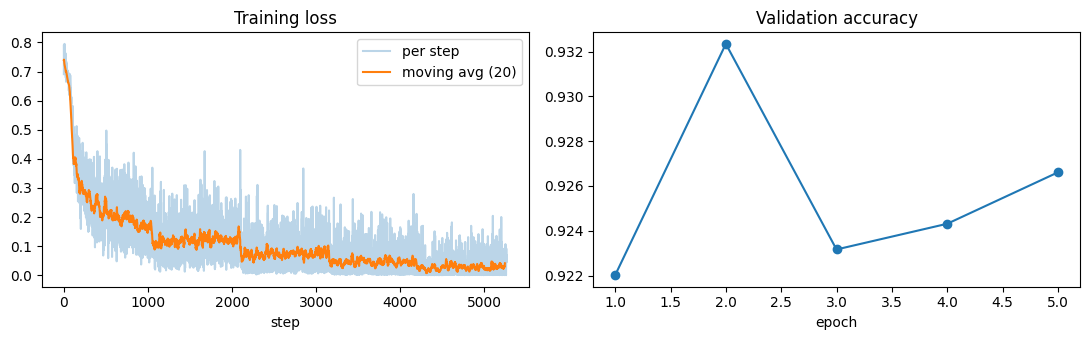

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sl = np.array(history["step_loss"])
ax[0].plot(sl, alpha=0.3, label="per step")
ax[0].plot(np.convolve(sl, np.ones(20)/20, mode="valid"), label="moving avg (20)")
ax[0].set_title("Training loss"); ax[0].set_xlabel("step"); ax[0].legend()
ax[1].plot(range(1, EPOCHS+1), history["val_acc"], marker="o")
ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

Once the model is fine-tuned, we want to use it to make predictions for new inputs. The `predict()` method below function runs the fine-tuned model on new, unlabeled text. With gradients disabled and the model in eval mode, it tokenizes the input sentences (truncating to `MAX_LEN` and padding them to a common length within the batch), moves them to the device, and passes them through the model to get logits. A softmax converts the logits into class probabilities, and for each text it prints the predicted label (via the `id2label` mapping) together with the model's confidence, e.g. "positive (97.31%)".

Note that `texts` must be a list of strings (a single string would be treated as one character sequence by the tokenizer, so wrap it as `["great movie"]`), and the function only prints results. If you want to reuse the predictions programmatically, have it return the labels and probabilities instead. Also keep in mind that softmax probabilities reflect the model's confidence, not guaranteed correctness, and fine-tuned models can be overconfident on out-of-distribution inputs.

In [21]:
@torch.no_grad()
def predict(texts):
    model.eval()
    enc = tokenizer(texts, truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt").to(DEVICE)
    logits = model(**enc).logits
    probs = torch.softmax(logits, dim=-1)       # logits -> probabilities
    for t, p in zip(texts, probs):
        k = int(p.argmax())
        print(f"{id2label[k]:8s} ({p[k]:.2%})  {t}")

Let's get the predictions for some simple example sentences.

In [22]:
reviews = [
    "An absolute masterpiece, I loved every minute.",
    "Boring, predictable, and far too long.",
    "Not bad, but not great either.",
    "I didn't hate it.",
]

predict(reviews)

positive (99.99%)  An absolute masterpiece, I loved every minute.
negative (99.97%)  Boring, predictable, and far too long.
negative (56.22%)  Not bad, but not great either.
positive (99.96%)  I didn't hate it.


Instead of writing our own `predict()` method, we can wrap the fine-tuned model and its tokenizer in a Hugging Face `pipeline`, which handles the whole inference workflow in a single object. Calling `pipeline("text-classification", model=model, tokenizer=tokenizer)` creates a ready-to-use classifier that tokenizes the input, runs the model in eval mode without gradients, applies softmax, and returns the predicted label with its confidence score. This removes the need to manage padding, device placement, or the argmax and label mapping by hand, and it accepts either a single string or a list of texts. Because the pipeline is a standard, reusable component, it is also easier to share, save, and plug into other applications, though the hand-written `predict()` remains useful when you want full control over the intermediate steps.

In [23]:
classifier = pipeline("text-classification", 
                      model=model, 
                      tokenizer=tokenizer,
                      device=DEVICE)

If we pass the same example sentences to the pipeline, we should naturally see the same results.

In [24]:
for idx, prediction in enumerate(classifier(reviews)):
    print(f"{prediction['label']:8s} ({prediction['score']:.2%})  {reviews[idx]}")

positive (99.99%)  An absolute masterpiece, I loved every minute.
negative (99.97%)  Boring, predictable, and far too long.
negative (56.22%)  Not bad, but not great either.
positive (99.96%)  I didn't hate it.


For this notebook, we judge the quality of the sentiment classifier in a deliberately lightweight way: by looking at the F1 score on held-out data and a handful of example predictions. F1 gives a compact, single-number summary of how well the model balances precision and recall, while the examples offer an intuitive sanity check that the outputs look sensible on real sentences. A more rigorous evaluation would go further, for instance with a detailed error analysis that examines confusion matrices, systematic failure modes (such as negation, sarcasm, or mixed sentiment), performance on different subgroups, and robustness to out-of-distribution inputs. Such an analysis is valuable for understanding where and why the model fails, but it is considerably more involved and therefore beyond the scope of this notebook.

**Important:** Before training the second model with the `transformers` library, we release the memory still held by the first one. The custom model, its optimizer (AdamW keeps two extra state tensors per parameter), and the scheduler all keep tensors alive on the device, and if they stay allocated the second model may run out of memory or train more slowly. The cleanup works in three steps:

- **`del model, optimizer, scheduler`:** removes the Python references, since memory can only be freed once nothing points to it. Leftover variables such as `batch`, `loss`, or the logits should be deleted too.
- **`gc.collect()`:** runs Python's garbage collector to reclaim objects that are no longer referenced, including reference cycles.
- **`torch.cuda.empty_cache()` / `torch.mps.empty_cache()`:** PyTorch keeps freed GPU memory in a cache for reuse, so these calls return the unused blocks to the system. The first applies to NVIDIA GPUs and the second to Apple Silicon. Each is wrapped in `try/except`, so the cell runs on any machine, including a CPU-only one, where neither call is needed.

In [25]:
try:
    del model, optimizer, scheduler
except:
    pass
gc.collect()
try:
    torch.cuda.empty_cache()
except:
    pass
try:
    torch.mps.empty_cache()
except:
    pass

### Approach 2: `Trainer` Class

We now repeat the fine-tuning with the `Trainer` class, which takes over the training loop, optimization, scheduling, evaluation, and checkpointing, so we need far less code than in the manual approach. To make the comparison fair and start from scratch, we load a fresh copy of the pretrained model instead of reusing the one we already fine-tuned, which would otherwise continue training from its updated weights. The code is the same as before: `from_pretrained` loads the pretrained `bert-base-uncased` encoder and attaches a new, randomly initialized token classification head with `num_labels=len(label_list)` outputs, `id2label` and `label2id` store our label mappings in the model configuration, and `.to(DEVICE)` moves the model to the chosen device. Reloading therefore resets the classification head to random values, so both approaches begin from the same starting point.

In [26]:
model = BertForSequenceClassification.from_pretrained(
    MODEL_NAME, 
    num_labels=2, 
    id2label=id2label, 
    label2id=label2id
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


The `Trainer` takes care of the evaluation loop, but it does not know which metrics matter for the task. By default it only reports the loss, which says little about how well sentiment labels are predicted. The `compute_metrics()` function we pass to the `Trainer` fills this gap: after each evaluation, the `Trainer` calls it with the model's raw logits and the true label IDs for the whole validation set, and the function returns a dictionary of metrics that is logged and can be used to select the best checkpoint (e.g., via `metric_for_best_model="f1"`).

This method receives an `eval_pred` tuple of the model's raw logits and the true labels, converts the logits to predicted classes with `argmax`, and returns a dictionary with accuracy and F1 (computed via [scikit-learn](https://scikit-learn.org/)). The `Trainer` logs these metrics alongside the evaluation loss. As before, `f1_score` defaults to binary averaging, so multi-class tasks need `average="macro"` or `"weighted"`.

In [27]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1": f1_score(labels, preds),
    }

The code below hands the whole training loop to the Hugging Face `Trainer`, which replaces the manual loop we wrote earlier (zeroing gradients, backpropagation, clipping, optimizer and scheduler steps, and evaluation) with a single high-level API.

- **Configure (`TrainingArguments`):** Defines the hyperparameters and behavior, such as learning rate, batch size, number of epochs, evaluation and logging frequency, and where to save checkpoints; we use the same arguments as for the "manual" approach for a fair comparison.
- **Assemble (`Trainer`):** Combines the model, the training arguments, the train and validation datasets, and `compute_metrics` into one object that knows how to train and evaluate.
- **Train (`trainer.train()`):** Runs the actual fine-tuning, looping over epochs and batches, updating the weights, and evaluating on the validation set with the metrics we defined.

In [28]:
args = TrainingArguments(
    output_dir=f"{output_folder}bert-sst2-trainer",
    num_train_epochs=EPOCHS,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=warmup_steps,         # replaces warmup_ratio
    max_grad_norm=1.0,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=False,
    metric_for_best_model="accuracy",
    save_total_limit=2,
    logging_steps=50,
    seed=42,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    data_collator=collator,            # dynamic padding, as before
    compute_metrics=compute_metrics,
)

trainer.train();

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.168756,0.218937,0.920872,0.922559
2,0.112669,0.245240,0.920872,0.924425
3,0.076633,0.234786,0.923165,0.924804
4,0.059035,0.277058,0.925459,0.926719
5,0.032009,0.330897,0.919725,0.922222


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Of course, like before, we can create a `pipeline` to use the fine-tuned model to make predictions in a convenient way.

In [29]:
classifier = pipeline("text-classification", 
                      model=model, 
                      tokenizer=tokenizer,
                      device=DEVICE)

Given that we now have a newly fine-tuned model &mdash; even though we used the same pretrained BERT model and the same training dataset &mdash; the results are likely to be slightly different, but overall in the same ballpark. Fine-tuning involves several sources of randomness, so two runs from the same pretrained BERT and the same data will not produce identical models. The classification head is randomly initialized, dropout masks differ, and the training data is shuffled into different batches each epoch. Unless every seed is fixed (and even then, some GPU operations are nondeterministic), these differences lead the optimizer down slightly different paths and to slightly different final weights.

Because the pretrained encoder, the data, and the hyperparameters are the same, however, the runs converge to similar solutions. Metrics such as accuracy and F1 therefore typically vary only by a small margin (often a few tenths of a percentage point on a task like SST-2), so the results are likely to differ slightly but remain in the same ballpark.

In [30]:
for idx, prediction in enumerate(classifier(reviews)):
    print(f"{prediction['label']:8s} ({prediction['score']:.2%})  {reviews[idx]}")

positive (99.98%)  An absolute masterpiece, I loved every minute.
negative (99.95%)  Boring, predictable, and far too long.
negative (99.07%)  Not bad, but not great either.
positive (99.74%)  I didn't hate it.


---

## Summary

In this notebook, we fine-tuned a pretrained BERT model for sentiment analysis, taking it from a randomly initialized classification head performing at chance level to a classifier that makes sensible predictions on new text. Along the way, we covered the full workflow: preparing and tokenizing the data, loading the pretrained model, establishing a baseline, training, monitoring progress, evaluating, and finally running inference. Our aim was never state-of-the-art performance, but a clear understanding of what happens at each step.

A central part of this was fine-tuning itself, which we approached in two ways. First, we wrote the training loop by hand, making every ingredient explicit: clearing gradients, the forward pass, backpropagation, gradient clipping, and the optimizer and learning rate scheduler updates. Then we used the Hugging Face `Trainer`, which packages these same steps behind a concise, configurable interface. Seeing both side by side shows what the wrapper does for us, and when it is worth dropping down to the manual approach for more control. The same holds for inference, where we compared a hand-written `predict()` function with a ready-made `pipeline`.

The practical value of this recipe extends far beyond movie reviews. Classification is one of the most widespread tasks in applied machine learning, underlying spam filtering, content moderation, customer support ticket routing, intent detection in chatbots, document categorization, medical text triage, and many more. Because the workflow stays essentially the same across these use cases, with only the data, the label set, and the number of output classes changing, the skills practiced here transfer directly. With this foundation, you are well equipped to adapt the notebook to your own classification problems and to explore more advanced topics such as hyperparameter tuning, error analysis, and larger models.

**Disclaimer:** This Jupyter Notebook contains content generated with the assistance of AI. While every effort has been made to review and validate the outputs, users should independently verify critical information before relying on it. The SELENE notebook repository is constantly evolving. We recommend downloading or pulling the latest version of this notebook from Github.